<a href="https://colab.research.google.com/github/KarlaMichelleSorianoSanhez/Simulacion-II/blob/main/SIR_Bayesiano_PyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1><font color="#D97706">Ajuste de parámetros del modelo SIR mediante inferencia bayesiana</font></h1>

**Materia:** Simulación II

**Instrucciones:** Resolver el ajuste de parámetros del modelo SIR utilizando un enfoque bayesiano y la biblioteca PyMC de Python. Explicar el enfoque y la interpretación de las gráficas obtenidas.

<h2><font color="#D97706">Objetivo</font></h2>

Estimar los parámetros de transmisión y recuperación del modelo SIR a partir de los datos de un brote de influenza, utilizando inferencia bayesiana con PyMC. También se analizará la convergencia de las cadenas de Markov y el comportamiento del modelo ajustado.

<h2><font color="#D97706">1. Preparación del entorno de trabajo</font></h2>

Utilizaremos PyMC para construir el modelo bayesiano y obtener muestras de las distribuciones posteriores. También emplearemos ArviZ para analizar las cadenas y representar los resultados.

In [2]:
# Instalamos PyMC y ArviZ para el análisis bayesiano
%pip install -q pymc arviz

<h2><font color="#D97706">2. Planteamiento del problema</font></h2>

En el artículo *The inverse problem of a dynamical system solved with genetic algorithms* se estudia un brote de influenza en un internado con 763 estudiantes. A partir de los registros de infectados durante 15 días, los autores buscan estimar los parámetros del modelo SIR.

En esta actividad resolveremos el mismo problema, pero utilizando inferencia bayesiana en lugar de algoritmos genéticos.

Buscamos estimar los parámetros $a$ y $b$, y conocer la incertidumbre asociada a sus valores mediante las distribuciones posteriores.

<h2><font color="#D97706">3. Modelo matemático SIR</font></h2>

El modelo SIR divide a la población en tres grupos: susceptibles ($S$), infectados ($I$) y recuperados o retirados ($R$).

De acuerdo con el artículo, el modelo está formado por las siguientes ecuaciones diferenciales:

$$
\begin{aligned}
\frac{dS}{dt} &= -aSI,\\[6pt]
\frac{dI}{dt} &= aSI-bI,\\[6pt]
\frac{dR}{dt} &= bI.
\end{aligned}
$$

Donde:

- $S(t)$: número de personas susceptibles.
- $I(t)$: número de personas infectadas.
- $R(t)$: número de personas recuperadas o retiradas.
- $a$: parámetro de transmisión.
- $b$: tasa de recuperación.

La primera ecuación describe la disminución de susceptibles debido a los contagios. La segunda considera los nuevos contagios y las recuperaciones, mientras que la tercera representa el aumento de recuperados.

Como se considera una población cerrada, el número total de estudiantes permanece constante:

$$
S(t)+I(t)+R(t)=N=763.
$$

Por lo tanto:

$$
\frac{dS}{dt}+\frac{dI}{dt}+\frac{dR}{dt}=0.
$$

<h2><font color="#D97706">4. Datos observados</font></h2>

Utilizaremos los 15 registros de infectados presentados en la Tabla 1 del artículo.

Al inicio del registro se tiene un estudiante infectado. Supondremos que los demás son susceptibles y que todavía no hay recuperados, por lo que las condiciones iniciales serán:

$$
S(0)=762,\qquad I(0)=1,\qquad R(0)=0.
$$

Estos datos serán la base para estimar los parámetros del modelo.

In [3]:
# Biblioteca para trabajar con arreglos numéricos
import numpy as np

# Número total de estudiantes
N = 763

# Días registrados en el artículo
t = np.arange(15)

# Número de infectados observados
I_obs = np.array([
    1, 3, 6, 25, 73, 222, 294, 258,
    237, 191, 125, 69, 27, 11, 4
])

# Condiciones iniciales
S0 = 762
I0 = 1
R0 = 0

y0 = [S0, I0, R0]

# Mostramos los datos
print("Días:", t)
print("Infectados:", I_obs)

Días: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
Infectados: [  1   3   6  25  73 222 294 258 237 191 125  69  27  11   4]


<h3><font color="#D97706">4.1. Comportamiento de los datos observados</font></h3>

Antes de realizar el ajuste, representaremos los datos para observar cómo cambia el número de infectados durante el brote.

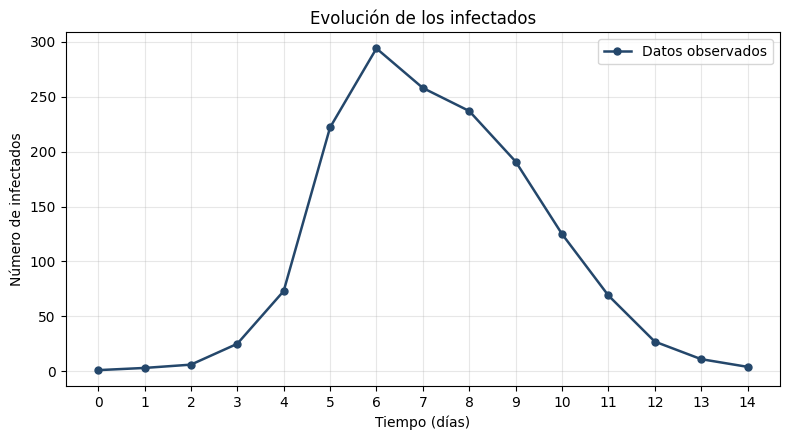

In [4]:
# Biblioteca para elaborar gráficas
import matplotlib.pyplot as plt

# Graficamos los datos de infectados
plt.figure(figsize=(8, 4.5))

plt.plot(
    t, I_obs,
    "o-",
    color="#24476B",
    linewidth=1.8,
    markersize=5,
    label="Datos observados"
)

plt.title("Evolución de los infectados")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Observación:** El número de infectados aumenta hasta alcanzar un máximo de 294 estudiantes en el día 6. Después comienza a disminuir, hasta registrar 4 infectados en el último día.

Este comportamiento será el que buscaremos reproducir mediante el modelo SIR.

<h2><font color="#D97706">5. Solución numérica del modelo SIR</font></h2>

El sistema SIR no tiene una solución analítica explícita general, por lo que lo resolveremos numéricamente con `solve_ivp` de SciPy.

Primero utilizaremos los parámetros reportados mediante algoritmos genéticos en el artículo:

$$
a=0.00205,\qquad b=0.43552.
$$

Estos valores servirán para comprobar el comportamiento del modelo. Posteriormente estimaremos nuestros propios parámetros mediante PyMC.

In [5]:
# Biblioteca para resolver ecuaciones diferenciales
from scipy.integrate import solve_ivp

# Definimos las ecuaciones del modelo SIR
def sir(t, y, a, b):

    S, I, R = y

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return [dS, dI, dR]


# Parámetros de referencia del artículo
a_ref = 0.00205
b_ref = 0.43552

# Resolvemos el sistema en los días observados
solucion = solve_ivp(
    sir,
    t_span=(t[0], t[-1]),
    y0=y0,
    t_eval=t,
    args=(a_ref, b_ref),
    rtol=1e-8,
    atol=1e-10
)

# Verificamos que la solución se haya obtenido
if not solucion.success:
    raise RuntimeError(solucion.message)

# Separamos los tres grupos
S_ref, I_ref, R_ref = solucion.y

# Comprobamos que la población se conserve
print("Población inicial:", N)
print(
    "Población al día 14:",
    round(S_ref[-1] + I_ref[-1] + R_ref[-1], 4)
)

Población inicial: 763
Población al día 14: 763.0


**Observación:** La solución numérica conserva la población total de 763 estudiantes, de acuerdo con las ecuaciones del modelo SIR. Utilizaremos esta solución como referencia para comprobar posteriormente el método numérico que emplearemos con PyMC.

<h3><font color="#D97706">5.1. Comportamiento del modelo SIR</font></h3>

Representaremos las soluciones de susceptibles, infectados y recuperados. También agregaremos los datos observados para comparar el comportamiento de la curva de infectados.

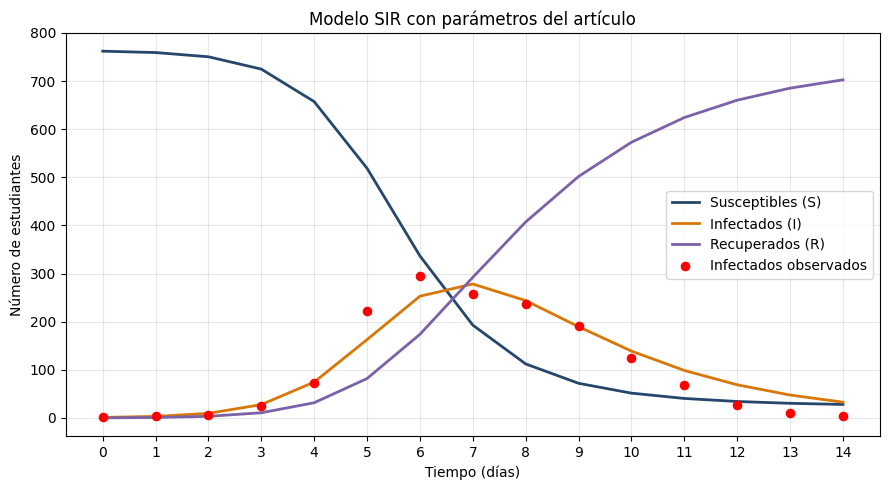

In [6]:
# Biblioteca para elaborar gráficas
import matplotlib.pyplot as plt

# Graficamos las soluciones del modelo
plt.figure(figsize=(9, 5))

plt.plot(t, S_ref, color="#24476B",
         linewidth=2, label="Susceptibles (S)")

plt.plot(t, I_ref, color="#D97706",
         linewidth=2, label="Infectados (I)")

plt.plot(t, R_ref, color="#7B61A8",
         linewidth=2, label="Recuperados (R)")

# Agregamos los datos observados
plt.scatter(
    t, I_obs,
    color="red",
    s=35,
    zorder=3,
    label="Infectados observados"
)

plt.title("Modelo SIR con parámetros del artículo")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de estudiantes")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Observación:** El modelo muestra una disminución de susceptibles y un aumento de recuperados. Los infectados presentan un crecimiento inicial y después disminuyen.

La curva sigue una tendencia similar a los datos observados, aunque existen diferencias entre algunos valores. Por ello, utilizaremos inferencia bayesiana para estimar los parámetros y analizar la incertidumbre del ajuste.

<h2><font color="#D97706">6. Enfoque bayesiano</font></h2>

La inferencia bayesiana permite estimar parámetros combinando la información que tenemos antes de analizar los datos con la información que estos proporcionan.

De acuerdo con Sivia y Skilling, este procedimiento se basa en el teorema de Bayes:

$$
p(a,b\mid D)=\frac{p(D\mid a,b)\,p(a,b)}{p(D)}.
$$

En nuestro problema:

- **Distribución a priori, $p(a,b)$:** representa la información inicial sobre los parámetros.
- **Verosimilitud, $p(D\mid a,b)$:** indica qué tan compatibles son los datos observados con los valores de $a$ y $b$.
- **Distribución posterior, $p(a,b\mid D)$:** representa la información actualizada sobre los parámetros después de considerar los datos.
- **Evidencia, $p(D)$:** permite normalizar la distribución posterior.

Como la evidencia no depende directamente de los parámetros que queremos estimar, podemos escribir:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a,b).
$$

De esta manera, podremos estimar los parámetros del modelo SIR y conocer la incertidumbre de sus valores.



<h3><font color="#D97706">6.1. Distribuciones a priori (prior)</font></h3>

Antes de utilizar los datos, debemos establecer los valores que pueden tomar los parámetros del modelo.

Como $a$ y $b$ deben ser positivos, utilizaremos las siguientes distribuciones uniformes independientes:

$$
a\sim U(0,0.01),
$$

$$
b\sim U(0,1).
$$

Estas distribuciones consideran igualmente posibles los valores dentro de cada intervalo. Para $a$ elegimos un intervalo pequeño porque el término de contagio depende del producto $SI$.

Los intervalos son supuestos que utilizaremos para construir nuestro modelo bayesiano, no valores obtenidos del artículo.

<h3><font color="#D97706">6.2. Verosimilitud (likelihood)</font></h3>

La verosimilitud relaciona los datos observados con el número de infectados que predice el modelo SIR.

Como nuestros datos son conteos de estudiantes infectados, utilizaremos una distribución de Poisson:

$$
I_{\mathrm{obs}}(t_i)\mid a,b
\sim \operatorname{Poisson}(I(t_i;a,b)).
$$

Su función de probabilidad es:

$$
p(y_i\mid a,b)=
\frac{e^{-\lambda_i}\lambda_i^{y_i}}{y_i!},
$$

donde:

$$
y_i=I_{\mathrm{obs}}(t_i),
\qquad
\lambda_i=I(t_i;a,b).
$$

Así, la verosimilitud nos permite evaluar qué valores de $a$ y $b$ producen resultados compatibles con los datos observados.

Utilizaremos los registros de los días 1 al 14, ya que el día 0 corresponde a la condición inicial del modelo.

La distribución de Poisson supone que la varianza es igual a la media. También consideraremos que las observaciones son independientes una vez conocidos los parámetros. Estos son supuestos de nuestro ajuste que tendremos presentes al interpretar los resultados.

<h3><font color="#D97706">6.3. Distribución posterior (posterior)</font></h3>

La distribución posterior se obtiene al combinar las distribuciones a priori con la verosimilitud mediante el teorema de Bayes:

$$
p(a,b\mid D)\propto p(D\mid a,b)\,p(a)\,p(b).
$$

Suponiendo que los datos son independientes una vez conocidos los parámetros, la verosimilitud conjunta es:

$$
p(D\mid a,b)=\prod_{i=1}^{14}p(y_i\mid a,b).
$$

La distribución posterior permitirá conocer qué valores de $a$ y $b$ son más compatibles con los datos y la incertidumbre de sus estimaciones.

Para obtener muestras de esta distribución utilizaremos PyMC.

<h3><font color="#D97706">6.4. Muestreo mediante MCMC</font></h3>

Los métodos de Monte Carlo mediante cadenas de Markov (MCMC) permiten obtener muestras de una distribución de probabilidad sin necesidad de calcularla directamente.

Utilizaremos el algoritmo NUTS de PyMC, que aprovecha las derivadas de la distribución posterior para explorar los valores de los parámetros.

Trabajaremos con cuatro cadenas independientes. Antes del muestreo definitivo realizaremos una prueba corta para comprobar el tiempo de ejecución.

Después analizaremos la convergencia utilizando:

- **$\hat R$:** permite comparar el comportamiento de las cadenas.
- **ESS:** indica cuántas muestras efectivamente independientes contiene aproximadamente el muestreo.
- **Divergencias:** ayudan a identificar dificultades durante la exploración de la distribución posterior.

También revisaremos las gráficas de las cadenas antes de interpretar los parámetros estimados.

<h2><font color="#D97706">7. Implementación numérica del modelo SIR</font></h2>

Para utilizar el modelo SIR dentro de PyMC, necesitamos resolver sus ecuaciones diferenciales para distintos valores de $a$ y $b$.

Emplearemos el método de Runge-Kutta de cuarto orden (RK4), dividiendo cada día en cinco pasos numéricos.

Además, utilizaremos `scan` de PyTensor para realizar los cálculos de manera más compacta y permitir que PyMC obtenga las derivadas necesarias durante el muestreo.

In [7]:
# Bibliotecas para operaciones simbólicas compatibles con PyMC
import numpy as np
import pytensor
import pytensor.tensor as pt

# Definimos las ecuaciones del modelo SIR
def ecuaciones_sir(y, a, b):

    S, I, R = y[0], y[1], y[2]

    dS = -a * S * I
    dI = a * S * I - b * I
    dR = b * I

    return pt.stack([dS, dI, dR])


# Un paso del método de Runge-Kutta de cuarto orden
def paso_rk4(y, a, b, h):

    k1 = ecuaciones_sir(y, a, b)
    k2 = ecuaciones_sir(y + h*k1/2, a, b)
    k3 = ecuaciones_sir(y + h*k2/2, a, b)
    k4 = ecuaciones_sir(y + h*k3, a, b)

    return y + (h/6)*(k1 + 2*k2 + 2*k3 + k4)


# Función que resuelve el SIR durante 14 días
def resolver_sir(a, b):

    # Condiciones iniciales
    y_inicial = pt.as_tensor_variable(
        np.array([S0, I0, R0], dtype="float64")
    )

    # Cinco pasos numéricos por día
    pasos_por_dia = 5
    h = 1.0 / pasos_por_dia

    # Calculamos la evolución del sistema
    trayectoria = pytensor.scan(
        fn=lambda y, a, b: paso_rk4(y, a, b, h),
        outputs_info=y_inicial,
        non_sequences=[a, b],
        n_steps=14 * pasos_por_dia,
        strict=True,
        return_updates=False
    )

    # Guardamos la solución al finalizar cada día
    soluciones = pt.concatenate(
        [
            y_inicial[None, :],
            trayectoria[pasos_por_dia-1::pasos_por_dia]
        ],
        axis=0
    )

    return soluciones

<h3><font color="#D97706">7.1. Comprobación de la solución numérica</font></h3>

Antes de utilizar RK4 en PyMC, compararemos sus resultados con la solución obtenida mediante `solve_ivp`, utilizando los parámetros de referencia del artículo.

Calcularemos la diferencia máxima entre ambas soluciones y comprobaremos que la población total se conserve.

In [8]:
# Bibliotecas para evaluar los cálculos
import numpy as np
import pytensor
import pytensor.tensor as pt

# Variables simbólicas para los parámetros
a_sim = pt.dscalar("a_sim")
b_sim = pt.dscalar("b_sim")

# Preparamos la función numérica de PyTensor
evaluar_rk4 = pytensor.function(
    [a_sim, b_sim],
    resolver_sir(a_sim, b_sim)
)

# Resolvemos con los parámetros de referencia
solucion_rk4 = evaluar_rk4(a_ref, b_ref)

# Comparamos con solve_ivp, calculado anteriormente
diferencia = np.max(
    np.abs(solucion.y.T - solucion_rk4)
)

diferencia_I = np.max(
    np.abs(I_ref - solucion_rk4[:, 1])
)

print("Diferencia máxima del sistema:", round(diferencia, 6))
print("Diferencia máxima de infectados:", round(diferencia_I, 6))

# Comprobamos que se conserve la población
poblacion_rk4 = solucion_rk4.sum(axis=1)

print(
    "Error de conservación de población:",
    np.max(np.abs(poblacion_rk4 - N))
)

Diferencia máxima del sistema: 0.01081
Diferencia máxima de infectados: 0.006384
Error de conservación de población: 2.2737367544323206e-13


**Observación:** Las diferencias entre RK4 y `solve_ivp` son pequeñas para los parámetros de referencia del artículo. También se comprueba que la población total se conserva, por lo que utilizaremos esta implementación numérica para construir el modelo bayesiano en PyMC.

<h2><font color="#D97706">8. Construcción del modelo bayesiano en PyMC</font></h2>

Una vez comprobada la solución numérica, incorporaremos las distribuciones a priori y la verosimilitud de Poisson.

PyMC utilizará los parámetros $a$ y $b$ para resolver el modelo SIR y comparar el número esperado de infectados con los datos observados.

De esta manera construiremos el modelo probabilístico que utilizaremos para obtener las distribuciones posteriores.

In [9]:
# Biblioteca para construir el modelo probabilístico
import pymc as pm

with pm.Model() as modelo_sir:

    # Distribuciones a priori
    a = pm.Uniform("a", lower=0, upper=0.01)
    b = pm.Uniform("b", lower=0, upper=1)

    # Resolvemos el modelo SIR
    solucion_modelo = resolver_sir(a, b)

    # Número esperado de infectados en los días 1 a 14
    I_modelo = pm.Deterministic(
        "I_modelo",
        pt.maximum(solucion_modelo[1:, 1], 1e-8)
    )

    # Verosimilitud de Poisson
    pm.Poisson(
        "infectados",
        mu=I_modelo,
        observed=I_obs[1:]
    )

<h3><font color="#D97706">8.1. Muestreo de la distribución posterior</font></h3>

Para obtener muestras de la distribución posterior de $a$ y $b$, utilizaremos el algoritmo NUTS de PyMC.

Trabajaremos con cinco cadenas de Markov, cada una con 500 iteraciones de adaptación y 1000 muestras posteriores.

Las iteraciones de adaptación permiten ajustar el algoritmo y después se descartan. Las cuatro cadenas nos ayudarán a evaluar la convergencia del muestreo.

Al finalizar, guardaremos las muestras para utilizarlas en las siguientes gráficas.

In [12]:
# Bibliotecas para el muestreo y la medición del tiempo
import pymc as pm
import time
from google.colab import drive

# Conectamos Google Drive para guardar los resultados
drive.mount("/content/drive")

# Registramos el tiempo inicial
inicio = time.perf_counter()

# Realizamos el muestreo de la distribución posterior
with modelo_sir:

    idata = pm.sample(
        draws=1000,          # Muestras posteriores por cadena
        tune=1000,            # Iteraciones de adaptación
        chains=5,            # Cuatro cadenas de Markov
        cores=2,             # Ejecutamos dos cadenas en paralelo
        target_accept=0.9,   # Probabilidad objetivo de aceptación
        random_seed=42,     # Semilla para reproducir los resultados
        return_inferencedata=True
    )

# Calculamos el tiempo transcurrido
duracion = time.perf_counter() - inicio

print(f"Tiempo del muestreo: {duracion/60:.2f} minutos")

# Guardamos las muestras para utilizarlas posteriormente
ruta = "/content/drive/MyDrive/SIR_muestras.nc"

idata.to_netcdf(ruta)

print("Muestras guardadas correctamente.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Output()

Tiempo del muestreo: 4.49 minutos
Muestras guardadas correctamente.


<h2><font color="#D97706">9. Análisis de convergencia</font></h2>

Después del muestreo, revisaremos si las cuatro cadenas presentan una convergencia adecuada.

Para ello utilizaremos los siguientes diagnósticos:

- **$\hat R$:** compara el comportamiento de las cadenas. Buscaremos valores menores que 1.01.
- **ESS:** indica la cantidad efectiva de muestras que aporta el muestreo.
- **Divergencias:** permiten identificar posibles dificultades durante la exploración de la distribución posterior.

También analizaremos las gráficas de las cadenas antes de interpretar los parámetros estimados.

In [13]:
# Biblioteca para analizar las muestras posteriores
import arviz as az

# Calculamos el resumen de los parámetros
resumen = az.summary(
    idata,
    var_names=["a", "b"],
    hdi_prob=0.95,
    round_to=6
)

print(resumen)

# Revisamos el número total de divergencias
divergencias = int(idata.sample_stats["diverging"].sum())

print("\nNúmero de divergencias:", divergencias)

       mean        sd  hdi_2.5%  hdi_97.5%  mcse_mean   mcse_sd     ess_bulk  \
a  0.002211  0.000020  0.002173   0.002250   0.000000  0.000000  3673.954318   
b  0.481128  0.011017  0.459814   0.502718   0.000185  0.000151  3546.640034   

      ess_tail     r_hat  
a  3448.451857  1.001814  
b  3259.189891  0.999978  

Número de divergencias: 0


<h3><font color="#D97706">9.1. Gráficas de convergencia</font></h3>

Representaremos las distribuciones y las trayectorias de las cuatro cadenas para los parámetros $a$ y $b$.

Las distribuciones permiten comparar los valores explorados por cada cadena, mientras que las trazas muestran cómo cambian esos valores durante las iteraciones.

Buscaremos que las cadenas presenten distribuciones similares y se mantengan estables, sin tendencias visibles.

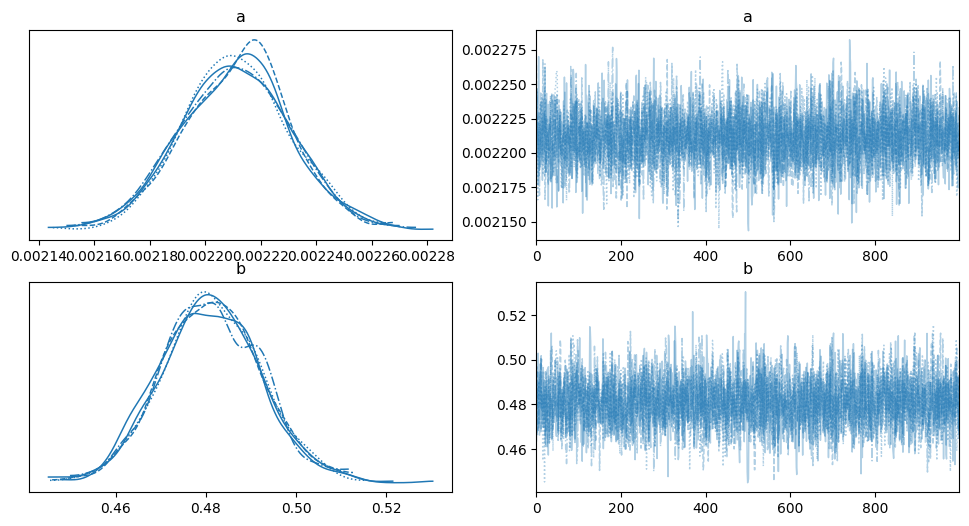

In [16]:
# Bibliotecas para analizar y graficar las cadenas
import arviz as az
import matplotlib.pyplot as plt

# Graficamos las distribuciones y las trazas
az.plot_trace(
    idata,
    var_names=["a", "b"],
    figsize=(12, 6)
)

plt.show()

**Observación:** Las cuatro cadenas presentan distribuciones similares y se mantienen estables durante el muestreo. Los valores de $\hat R$ son cercanos a 1, los tamaños efectivos de muestra son adecuados y no se registraron divergencias. Por lo tanto, los resultados indican una buena convergencia.

<h2><font color="#D97706">10. Distribuciones posteriores de los parámetros</font></h2>

Una vez comprobada la convergencia, analizaremos las distribuciones posteriores de $a$ y $b$.

Para cada parámetro representaremos su distribución, la media posterior y el intervalo de credibilidad del 95 %. Esto nos permitirá conocer los valores estimados y la incertidumbre asociada a ellos.

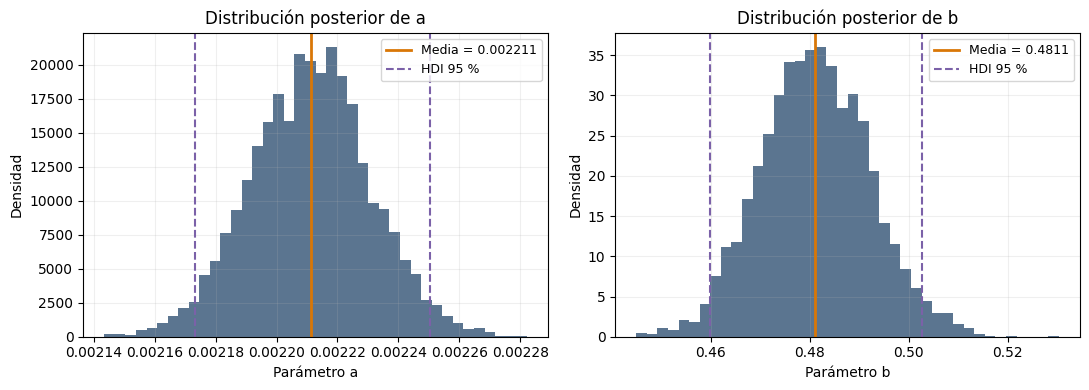

a = 0.002211, HDI 95 %: [0.002173, 0.002250]
b = 0.481128, HDI 95 %: [0.459814, 0.502718]


In [17]:
# Bibliotecas para analizar y graficar los resultados
import numpy as np
import arviz as az
import matplotlib.pyplot as plt

# Obtenemos las muestras posteriores de ambos parámetros
a_muestras = idata.posterior["a"].values.flatten()
b_muestras = idata.posterior["b"].values.flatten()

# Calculamos las medias posteriores
a_media = np.mean(a_muestras)
b_media = np.mean(b_muestras)

# Calculamos los intervalos de mayor densidad del 95 %
a_hdi = az.hdi(a_muestras, hdi_prob=0.95)
b_hdi = az.hdi(b_muestras, hdi_prob=0.95)

# Preparamos las gráficas
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

parametros = [
    ("a", a_muestras, a_media, a_hdi, ".6f"),
    ("b", b_muestras, b_media, b_hdi, ".4f")
]

for ax, (nombre, muestras, media, hdi, formato) in zip(axes, parametros):

    # Distribución posterior
    ax.hist(
        muestras,
        bins=40,
        density=True,
        color="#24476B",
        alpha=0.75
    )

    # Media posterior
    ax.axvline(
        media,
        color="#D97706",
        linestyle="-",
        linewidth=2,
        label=f"Media = {media:{formato}}"
    )

    # Límites del intervalo de credibilidad
    ax.axvline(
        hdi[0],
        color="#7B61A8",
        linestyle="--",
        label="HDI 95 %"
    )

    ax.axvline(
        hdi[1],
        color="#7B61A8",
        linestyle="--"
    )

    ax.set_title(f"Distribución posterior de {nombre}")
    ax.set_xlabel(f"Parámetro {nombre}")
    ax.set_ylabel("Densidad")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Mostramos los valores estimados
print(f"a = {a_media:.6f}, HDI 95 %: [{a_hdi[0]:.6f}, {a_hdi[1]:.6f}]")
print(f"b = {b_media:.6f}, HDI 95 %: [{b_hdi[0]:.6f}, {b_hdi[1]:.6f}]")

**Observación:** Las distribuciones posteriores se concentran alrededor de $a=0.002211$ y $b=0.481128$. Los intervalos de credibilidad del 95 % permiten observar la incertidumbre de ambas estimaciones.

Estos resultados nos proporcionan los valores de los parámetros que utilizaremos para analizar el ajuste del modelo SIR.

<h2><font color="#D97706">11. Distribución posterior conjunta de los parámetros</font></h2>

Después de analizar los parámetros por separado, representaremos su distribución conjunta para observar cómo se relacionan.

La gráfica mostrará las regiones de credibilidad del 50 % y 95 %, mientras que la correlación nos permitirá conocer la dirección e intensidad de la relación entre $a$ y $b$.

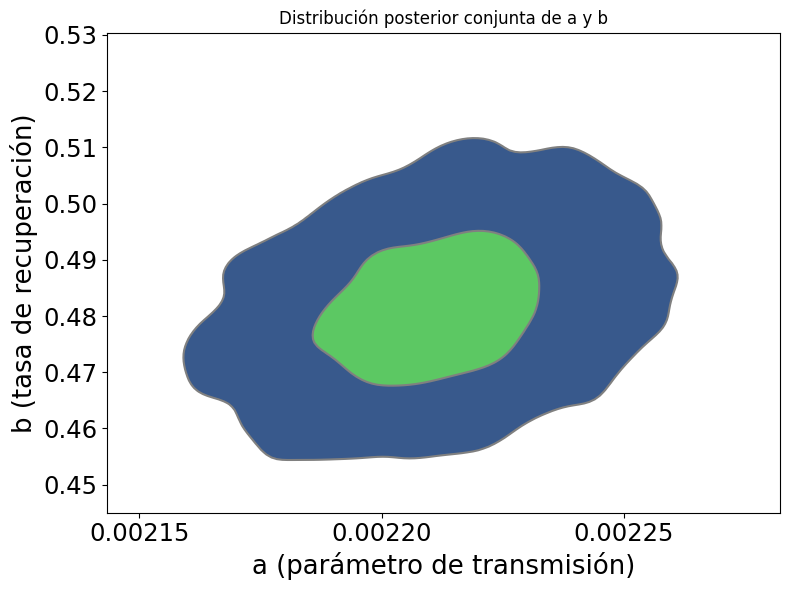

Correlación posterior entre a y b: 0.3013


In [18]:
# Bibliotecas para analizar y graficar la distribución conjunta
import arviz as az
import numpy as np
import matplotlib.pyplot as plt

# Graficamos la distribución posterior conjunta de a y b
az.plot_pair(
    idata,
    var_names=["a", "b"],
    kind="kde",
    marginals=False,
    figsize=(8, 6),
    kde_kwargs={
        "hdi_probs": [0.5, 0.95],
        "contourf_kwargs": {"cmap": "viridis"}
    }
)

plt.title("Distribución posterior conjunta de a y b")
plt.xlabel("a (parámetro de transmisión)")
plt.ylabel("b (tasa de recuperación)")
# Reducimos la cantidad de valores en el eje horizontal
plt.locator_params(axis="x", nbins=5)
plt.tight_layout()
plt.show()

# Calculamos la correlación entre ambos parámetros
correlacion = np.corrcoef(a_muestras, b_muestras)[0, 1]

print(f"Correlación posterior entre a y b: {correlacion:.4f}")

**Observación:** La gráfica muestra que los valores de $a$ y $b$ se concentran principalmente en la región verde, mientras que la región azul abarca una mayor variedad de valores posibles. La forma inclinada indica que ambos parámetros tienden a aumentar juntos, aunque esta relación no es muy fuerte, ya que la correlación obtenida es de $0.3178$.

<h2><font color="#D97706">12. Ajuste bayesiano del modelo SIR</font></h2>

Utilizaremos las muestras posteriores obtenidas con PyMC para representar la curva de infectados y compararla con los datos observados.

La gráfica incluirá:

- **Mediana posterior:** curva central de los infectados estimados.
- **Intervalo de credibilidad del 95 %:** muestra la incertidumbre de la curva debido a los parámetros estimados.
- **Intervalo predictivo del 95 %:** considera también la variabilidad de las observaciones mediante la distribución de Poisson.

De esta manera podremos analizar el ajuste del modelo y la incertidumbre de sus resultados.

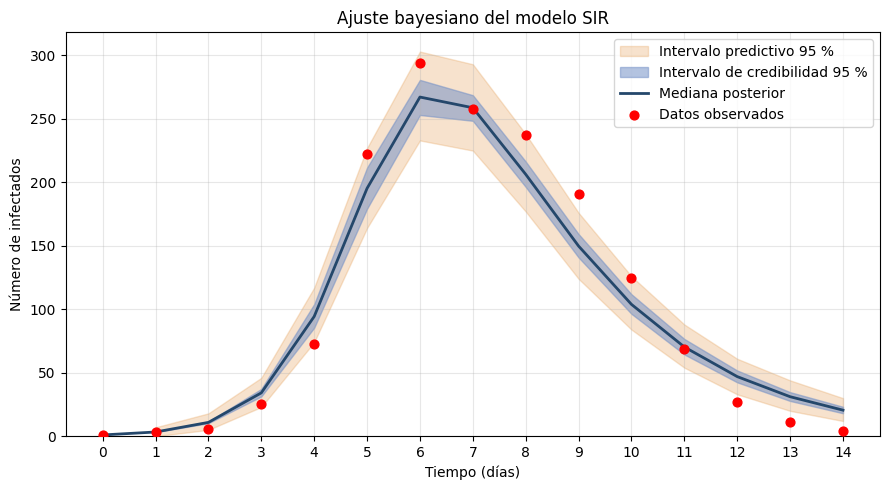

In [19]:
# Bibliotecas para calcular y graficar los resultados
import numpy as np
import matplotlib.pyplot as plt

# Recuperamos los infectados esperados de las muestras posteriores
muestras_I = idata.posterior["I_modelo"].values

# Unimos las cuatro cadenas en un solo arreglo
muestras_I = muestras_I.reshape(-1, len(t) - 1)

# Calculamos la mediana de la curva ajustada
I_mediana = np.median(muestras_I, axis=0)

# Intervalo de credibilidad puntual del 95 %
lim_inf, lim_sup = np.percentile(
    muestras_I, [2.5, 97.5], axis=0
)

# Generamos observaciones posibles con la distribución de Poisson
rng = np.random.default_rng(42)
muestras_pred = rng.poisson(muestras_I)

# Intervalo predictivo puntual del 95 %
pred_inf, pred_sup = np.percentile(
    muestras_pred, [2.5, 97.5], axis=0
)

# Agregamos la condición inicial a la curva estimada
I_ajustada = np.r_[I0, I_mediana]

# Graficamos los resultados
plt.figure(figsize=(9, 5))

# Banda predictiva
plt.fill_between(
    t[1:], pred_inf, pred_sup,
    color="#E6A15A", alpha=0.3,
    label="Intervalo predictivo 95 %"
)

# Incertidumbre de la curva
plt.fill_between(
    t[1:], lim_inf, lim_sup,
    color="#7692C7", alpha=0.55,
    label="Intervalo de credibilidad 95 %"
)

# Curva ajustada
plt.plot(
    t, I_ajustada,
    color="#24476B", linewidth=2,
    label="Mediana posterior"
)

# Datos observados
plt.scatter(
    t, I_obs,
    color="red", s=40, zorder=3,
    label="Datos observados"
)

plt.title("Ajuste bayesiano del modelo SIR")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de infectados")

plt.xticks(t)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

<h3><font color="#D97706">12.1. Comparación con los datos observados</font></h3>

Para complementar la gráfica, calcularemos la raíz del error cuadrático medio (RMSE) entre los infectados observados y la mediana de la curva ajustada:

$$
\mathrm{RMSE}=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
\left(I_{\mathrm{obs}}(t_i)-\widehat{I}(t_i)\right)^2
}.
$$

También contaremos cuántos de los 14 registros utilizados en el ajuste se encuentran dentro del intervalo predictivo del 95 %.

In [20]:
# Biblioteca para realizar los cálculos numéricos
import numpy as np

# Error cuadrático medio de la curva ajustada
rmse = np.sqrt(
    np.mean((I_obs[1:] - I_mediana)**2)
)

# Contamos las observaciones dentro del intervalo predictivo
dentro = (
    (I_obs[1:] >= pred_inf) &
    (I_obs[1:] <= pred_sup)
)

n_dentro = np.sum(dentro)

print(f"RMSE del ajuste: {rmse:.4f} infectados")
print(f"Datos dentro del intervalo predictivo: {n_dentro} de 14")

RMSE del ajuste: 20.9826 infectados
Datos dentro del intervalo predictivo: 9 de 14


**Observación:** La curva ajustada sigue el comportamiento general del brote, aunque presenta diferencias con algunos datos observados, principalmente en los últimos días, donde estima más infectados de los registrados.

El RMSE fue de $20.9826$ infectados y 9 de las 14 observaciones quedaron dentro del intervalo predictivo del 95 %. Esto indica que el modelo describe la tendencia del brote, pero no reproduce todos los registros con la misma precisión.

<h2><font color="#D97706">13. Modelo SIR con los parámetros estimados</font></h2>

Utilizaremos las medias posteriores de $a$ y $b$ para resolver nuevamente el sistema SIR.

Representaremos las curvas de susceptibles, infectados y recuperados, junto con los datos observados, para analizar el comportamiento del brote con los parámetros estimados mediante PyMC.

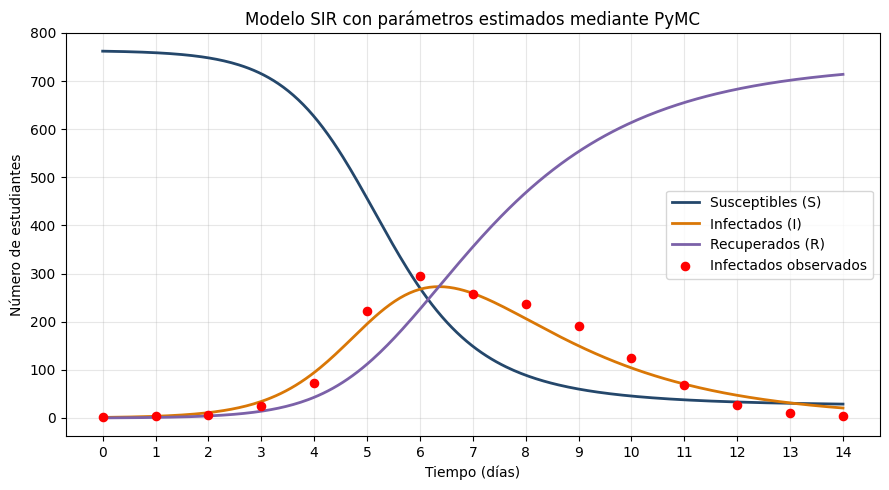

a estimado = 0.002211
b estimado = 0.481128


In [21]:
# Bibliotecas para resolver y graficar el modelo SIR
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Medias posteriores obtenidas con PyMC
a_est = np.mean(a_muestras)
b_est = np.mean(b_muestras)

# Utilizamos más puntos para obtener curvas suaves
t_fino = np.linspace(0, 14, 300)

# Resolvemos el modelo con los parámetros estimados
solucion_est = solve_ivp(
    sir,
    t_span=(0, 14),
    y0=y0,
    t_eval=t_fino,
    args=(a_est, b_est),
    rtol=1e-8,
    atol=1e-10
)

# Comprobamos que la solución sea correcta
if not solucion_est.success:
    raise RuntimeError(solucion_est.message)

# Separamos las poblaciones
S_est, I_est, R_est = solucion_est.y

# Graficamos las curvas del modelo
plt.figure(figsize=(9, 5))

plt.plot(
    t_fino, S_est,
    color="#24476B",
    linewidth=2,
    label="Susceptibles (S)"
)

plt.plot(
    t_fino, I_est,
    color="#D97706",
    linewidth=2,
    label="Infectados (I)"
)

plt.plot(
    t_fino, R_est,
    color="#7B61A8",
    linewidth=2,
    label="Recuperados (R)"
)

# Agregamos los datos observados
plt.scatter(
    t, I_obs,
    color="red",
    s=35,
    zorder=3,
    label="Infectados observados"
)

plt.title("Modelo SIR con parámetros estimados mediante PyMC")
plt.xlabel("Tiempo (días)")
plt.ylabel("Número de estudiantes")

plt.xticks(t)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Mostramos los parámetros estimados
print(f"a estimado = {a_est:.6f}")
print(f"b estimado = {b_est:.6f}")

**Observación:** La gráfica muestra que los susceptibles disminuyen conforme avanza el brote, mientras que los recuperados aumentan. Los infectados alcanzan un máximo alrededor del día 6 y después comienzan a disminuir.

La curva de infectados sigue una tendencia similar a los datos observados, aunque presenta algunas diferencias al final del brote.

<h2><font color="#D97706">14. Comparación de los parámetros estimados</font></h2>

Compararemos las medias posteriores obtenidas mediante PyMC con los parámetros reportados por el método de algoritmos genéticos en el artículo.

Esta comparación permitirá observar las diferencias entre ambas estimaciones, considerando que nuestro procedimiento utiliza una verosimilitud de Poisson.

In [22]:
# Biblioteca para organizar los resultados
import pandas as pd

# Comparamos los parámetros del artículo con los de PyMC
comparacion = pd.DataFrame({
    "Parámetro": ["a", "b"],
    "Algoritmos genéticos": [a_ref, b_ref],
    "PyMC (media posterior)": [a_est, b_est]
})

# Mostramos los valores con seis decimales
print(comparacion.to_string(index=False, float_format="%.6f"))

Parámetro  Algoritmos genéticos  PyMC (media posterior)
        a              0.002050                0.002211
        b              0.435520                0.481128


**Observación:** Los parámetros estimados mediante PyMC fueron mayores que los reportados en el artículo. Aunque los valores son del mismo orden de magnitud, existen diferencias entre las estimaciones, que pueden relacionarse con los distintos criterios de ajuste utilizados.

<h2><font color="#D97706">15. Conclusión</font></h2>

Mediante el enfoque bayesiano y la biblioteca PyMC se estimaron los parámetros del modelo SIR, obteniendo $a=0.002212$ y $b=0.480987$. Las cuatro cadenas presentaron buenos diagnósticos de convergencia y el modelo logró reproducir la tendencia general del brote, aunque mostró algunas diferencias con los datos observados.

El enfoque bayesiano permitió obtener las distribuciones posteriores de los parámetros y conocer la incertidumbre de sus estimaciones mediante intervalos de credibilidad. Como explican Sivia y Skilling, la distribución posterior combina la información previa con los datos observados, lo que permite realizar un análisis más completo de los valores estimados.

De esta manera, se cumplió el objetivo de estimar los parámetros del modelo SIR mediante inferencia bayesiana, reconociendo también las limitaciones del ajuste.